### Part 1 - Exploratory Data Analysis:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#!pip install --upgrade datasets transformers

In [ ]:
#!pip install -q torch seaborn wordcloud scikit-learn matplotlib nltk

In [ ]:
import json
import os
import re
import time
import string
import ast
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from math import ceil
from datetime import datetime
from collections import Counter
from mpl_toolkits.mplot3d import Axes3D
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from datasets import load_dataset
from transformers import pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.sparse import hstack

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Question 1 - Data exploration: 

In [ ]:
#Text preprocessing. Converting to lowercase, removing unecessary spacing, HTML and links
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def clean_row(row):
    row["text"] = clean_text(row["text"])
    return row

In [ ]:
#Checks for valid rating values
def is_valid_rating(value):
    try:
        value = float(value)
        return 1.0 <= value <= 5.0
    except (TypeError, ValueError, KeyError):
        return False

In [ ]:
#Converts numerical attributes from strings to floats
def convert_to_float(row):
    if "price" in row:
        row["price"] = float(row["price"])
    if "average_rating" in row:
        row["average_rating"] = float(row["average_rating"])
    if "rating" in row:
        row["rating"] = float(row["rating"])
    return row

In [ ]:
#Sets main category to one of the five categories: "Books", "Kindle_Store", "Electronics", "Amazon_Fashion","All_Beauty"
def set_main_category(row, category):
    row["main_category"] = category
    return row

In [ ]:
#Filters out rows with missing or invalid values 
def filter_valid_rows(row):
    features = row.get("features")
    if not features or len(features) == 0:   #If value is not valid or empty return False
        return False

    description = row.get("description")
    if not description or len(description) == 0:  
        return False

    if not row.get("parent_asin"):  
        return False

    try:
        price = float(row["price"])
        if price <= 0:
            return False
    except (TypeError, ValueError, KeyError):
        return False

    try:
        avg_rating = float(row["average_rating"])
        if not (1.0 <= avg_rating <= 5.0):
            return False
    except (TypeError, ValueError, KeyError):
        return False

    return True

In [ ]:
#Creates columns "year" and "year_month" using the value inside "timestamp"
def extract_date_fields(row):
    try:
        ts = pd.to_datetime(row["timestamp"], unit="ms")
        row["year"] = ts.year
        row["year_month"] = ts.to_period("M").strftime("%Y-%m")
    except (KeyError, TypeError, ValueError):
        row["year"] = None
        row["year_month"] = None
    return row

We only load review rows that have a non-empty ```parent_asin``` field. We also look for a non-empty ```text``` field and a valid ```rating```. A valid rating is between 1.0 and 5.0. We remove uneeded columns (images, helpful_vote, title etc.). We only load reviews that were made between a certain time period for future analysis.

In [ ]:
#Loads 5000 clean reviews
def load_clean_reviews(category, max_rows, matched_asins, output_dir="data", start_year=2016, end_year=2022):
    category_rev = "raw_review_" + category
    os.makedirs(output_dir, exist_ok=True)

    reviews_filepath = os.path.join(output_dir, f"{category}_reviews.csv")

    dataset = load_dataset(
        "McAuley-Lab/Amazon-Reviews-2023",
        category_rev,
        split="full",
        streaming=True,
        trust_remote_code=True
    )

    dataset = dataset.remove_columns(["helpful_vote","verified_purchase","title"])
    dataset = dataset.filter(lambda row: row.get("parent_asin"))
    dataset = dataset.filter(lambda row: row.get("text") and isinstance(row.get("text"), str) and row.get("text").strip() != '' and is_valid_rating(row.get("rating")))
    dataset = dataset.remove_columns(["images"])
    dataset = dataset.map(convert_to_float)
    dataset = dataset.map(clean_row)
    dataset = dataset.map(extract_date_fields)

    #Filter by year range
    dataset = dataset.filter(lambda row: row["year"] is not None and start_year <= row["year"] <= end_year)

    rows = []
    count = 0
    for row in dataset:
        asin = row.get("parent_asin")
        if asin not in matched_asins:
            continue

        rows.append(row)
        count += 1

        if len(rows) >= 100:
            df = pd.DataFrame(rows)
            df.to_csv(reviews_filepath, mode="a", index=False, header=not os.path.exists(reviews_filepath))
            rows = []

        if count >= max_rows:
            break

    if rows:
        df = pd.DataFrame(rows)
        df.to_csv(reviews_filepath, mode="a", index=False, header=not os.path.exists(reviews_filepath))

We remove all the unecessary columns (images, store, videos etc.) included in the metadata. We use the function ```filter_valid_rows()``` to load rows that do not have empty values in important fields. We also convert rating values from strings to floats and change the value inside the ```main_category``` column to depict the actual five product categories that we have chosen.

In [ ]:
#Loads 5000 clean metadata rows 
def load_clean_metadata(category, max_rows, fields_to_drop=None, output_dir="data"):
    category_meta = "raw_meta_" + category
    os.makedirs(output_dir, exist_ok=True)

    metadata_filepath = os.path.join(output_dir, f"{category}_metadata.csv")

    dataset = load_dataset(
        "McAuley-Lab/Amazon-Reviews-2023",
        category_meta,
        split="full",
        streaming=True,
        trust_remote_code=True
    )

    dataset = dataset.remove_columns(["store", "images", "videos", "details", "bought_together","categories","subtitle","author","title"])
    if fields_to_drop:
        dataset = dataset.remove_columns(fields_to_drop)

    dataset = dataset.filter(filter_valid_rows)
    dataset = dataset.map(convert_to_float)
    dataset = dataset.map(set_main_category, fn_kwargs={"category": category})

    rows = []
    count = 0
    asins = set()

    for row in dataset:
        rows.append(row)
        asins.add(row["parent_asin"])
        count += 1

        if len(rows) >= 100:
            df = pd.DataFrame(rows)
            df.to_csv(metadata_filepath, mode="a", index=False, header=not os.path.exists(metadata_filepath))
            rows = []

        if count >= max_rows:
            break

    if rows:
        df = pd.DataFrame(rows)
        df.to_csv(metadata_filepath, mode="a", index=False, header=not os.path.exists(metadata_filepath))

    return asins

In [ ]:
#Creates a csv with all 5000 rows for each product category
def create_csv(category, output_dir="data"):
    review_path = os.path.join(output_dir, f"{category}_reviews.csv")
    meta_path = os.path.join(output_dir, f"{category}_metadata.csv")
    path = os.path.join(output_dir, f"{category}_data.csv")

    reviews = pd.read_csv(review_path)
    metadata = pd.read_csv(meta_path)

    reviews.drop(columns=["timestamp"], inplace=True)   

    merged = pd.merge(reviews, metadata, on="parent_asin", how="inner")

    merged.to_csv(path, index=False)
    os.remove(review_path)
    os.remove(meta_path)

In [ ]:
product_categories = ["Books", "Kindle_Store", "Electronics", "Amazon_Fashion","All_Beauty"]

For our analysis we use 5000 rows from each product category from the *McAuley-Lab/Amazon-Reviews-2023* dataset. We work with 5 product categories, so we load 25000 rows in total.
We first load the metadata and then find corresponding reviews using the ```parent_asin``` key. All the reviews we load are dated between 2016 and 2022. We choose later years because we expect more data to be available than from past years.

In [ ]:
#mkdir /content/data

In [ ]:
#! cp -r /content/drive/MyDrive/data_5000_rows/* /content/data

In [ ]:
#! cp /content/drive/MyDrive/final_sentiment_scores.csv /content/final_sentiment_scores.csv

In [ ]:
max_rows = 5000
for i in product_categories:
  asins = load_clean_metadata(i, max_rows)
  load_clean_reviews(i, max_rows, asins)
  create_csv(i)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/30.3k [00:00<?, ?B/s]

Amazon-Reviews-2023.py:   0%|          | 0.00/39.6k [00:00<?, ?B/s]

In [ ]:
for category in product_categories:
    df = pd.read_csv(f"data/{category}_data.csv")
    num_unique_products = df['asin'].nunique()

    empty_text_rows = df[(df['text'].isna()) | (df['text'].apply(lambda x: isinstance(x, str) and x.strip() == ''))]

    df = df.drop(empty_text_rows.index)       #Remove empty rows

    df.to_csv(f"data/{category}_data.csv", index=False)

In [ ]:
for category in product_categories:
    df = pd.read_csv(f"data/{category}_data.csv")
    print(f"{category} - Num of unique products: {df['asin'].nunique()}")

Books - Num of unique products: 1397
Kindle_Store - Num of unique products: 1528
Electronics - Num of unique products: 1997
Amazon_Fashion - Num of unique products: 2908
All_Beauty - Num of unique products: 1563


Distribution of product ratings within each category:

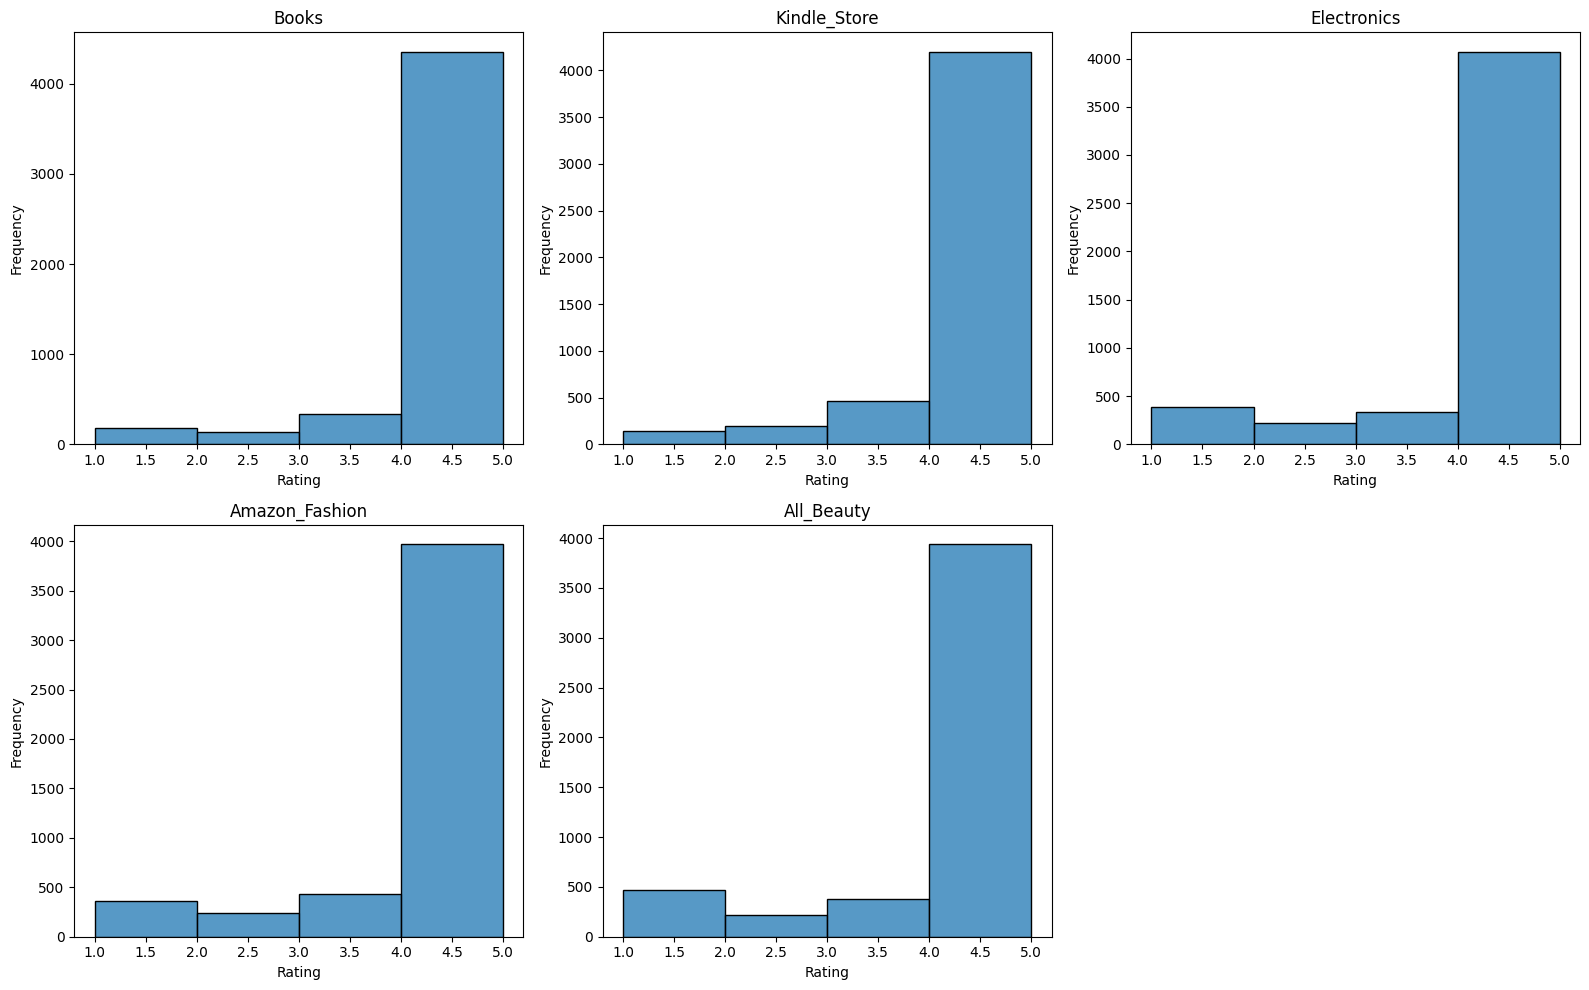

In [ ]:
dfs = []
for category in product_categories:
    df = pd.read_csv(f"data/{category}_data.csv")
    dfs.append(df)

all_reviews = pd.concat(dfs, ignore_index=True)

# Create one histogram per category
plt.figure(figsize=(16, 10))
for i, cat in enumerate(product_categories):
    ratings = all_reviews[all_reviews["main_category"] == cat]
    plt.subplot(2, 3, i+1)
    sns.histplot(ratings["rating"], bins=[1,2,3,4,5])
    plt.title(f"{cat}")
    plt.xlabel("Rating")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Average rating per category:

In [ ]:
avg_ratings = all_reviews.groupby("main_category")["rating"].mean().reset_index()
for index, row in avg_ratings.iterrows():
    print(f"{row['main_category']}: {row['rating']:.2f}")

All_Beauty: 4.22
Amazon_Fashion: 4.26
Books: 4.48
Electronics: 4.30
Kindle_Store: 4.37


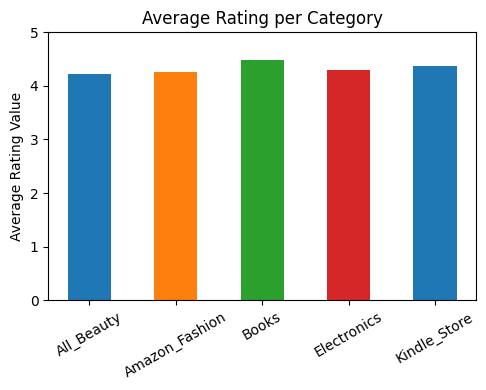

In [ ]:
categories = avg_ratings["main_category"]
ratings = avg_ratings["rating"]

plt.figure(figsize=(5, 4))
bars = plt.bar(categories, ratings, color = ["#1f77b4","#ff7f0e","#2ca02c","#d62728"],width=0.5)
plt.ylabel("Average Rating Value")
plt.title("Average Rating per Category")
plt.xlabel("")
plt.ylim(0, 5)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

We observe that average product ratings are consistently high and similar across all categories.

Identifying products with a high number of reviews and a low rating:

In [ ]:
product_stats = all_reviews.groupby("asin").agg(
    review_count=("text", "count"),avg_rating=("rating", "mean")).reset_index()

#find products with low rating (average rating below 3.0)
low_rating_products = product_stats[product_stats["avg_rating"] < 3.0]

review_threshold = product_stats["review_count"].quantile(0.90)  # Keep products with review count in the top 10%, based on review count

#find products with high review count among the low rating products
high_rev_low_rating_products = low_rating_products[low_rating_products["review_count"] > review_threshold]

In [ ]:
print("Products with low average rating and high number of reviews:\n")
print("ASIN".ljust(15), "Average Rating".ljust(20), "Review Count")
print("-" * 50)

for _, row in high_rev_low_rating_products.iterrows():
    print(f"{row['asin']:<15} {row['avg_rating']:<20.2f} {row['review_count']}")

Products with low average rating and high number of reviews:

ASIN            Average Rating       Review Count
--------------------------------------------------
1597809195      2.75                 8
B00011QUDE      2.57                 21
B00BD5FEMK      2.83                 6
B00Q970V5W      2.96                 26
B00X3LHKQA      2.67                 6
B0184ICVTW      2.71                 7
B01M7RAAI4      2.78                 9
B079KW81R1      2.83                 6
B07C5DPZC2      2.83                 6
B07F3RH7DD      2.43                 7
B07JJJSMCM      2.50                 6
B07PNNCSP9      2.88                 8
B08FFJWQY1      2.45                 20


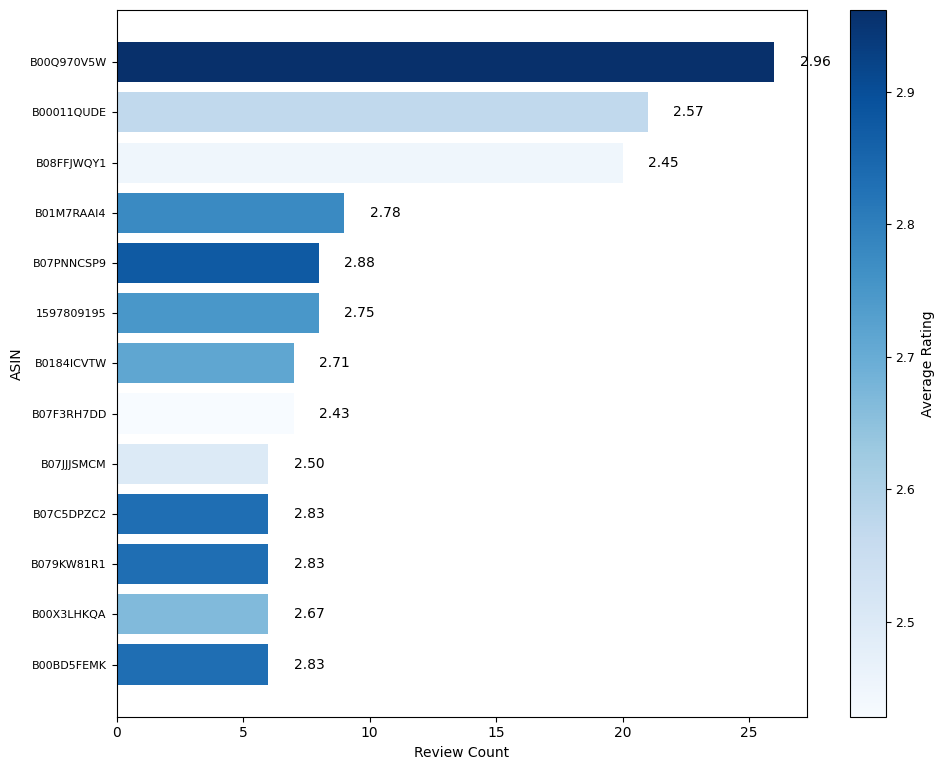

In [ ]:
sorted_products = high_rev_low_rating_products.sort_values("review_count", ascending=True)

norm = mcolors.Normalize(vmin=sorted_products["avg_rating"].min(), vmax=sorted_products["avg_rating"].max())
colors = plt.cm.Blues(norm(sorted_products["avg_rating"]))

bar_height = max(2, len(sorted_products) * 0.6)
fig, ax = plt.subplots(figsize=(10, bar_height))

bars = ax.barh(
    sorted_products["asin"],
    sorted_products["review_count"],
    color=colors
)

for bar, rating in zip(bars, sorted_products["avg_rating"]):
    ax.text(bar.get_width() + 1,bar.get_y() + bar.get_height() / 2,f"{rating:.2f}",va="center",fontsize=10)

sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, orientation="vertical", label="Average Rating")
cbar.ax.tick_params(labelsize=9)

ax.set_xlabel("Review Count")
ax.set_ylabel("ASIN")
ax.tick_params(axis='y', labelsize=8)

if len(sorted_products) == 1:
    ax.set_ylim(-0.2, 1)

plt.tight_layout()
plt.show()

We search for the most common words in the reviews found for these products. Given that they are low-rated we expect to find some negatively connoted words.

In [ ]:
stop_words = set(stopwords.words("english"))          #Removing stopwords
stop_words.update([
    "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten",    #frequently used words in reviews
    "amazon", "product", "buy", "bought","purchase", "item", "use", "used", "get"
])
lemmatizer = WordNetLemmatizer()

def text_preprocessing(text):
    text = text.lower()
    text = text.replace("’", "'")
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"\b(\w+)'s\b", r"\1", text)
    text = re.sub(r"'s\b", "", text)
    text = re.sub(r"'\w+", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))

    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2 and w != "s"]

    return " ".join(tokens)

In [ ]:
from wordcloud import WordCloud
relevant_products = all_reviews[all_reviews["asin"].isin(high_rev_low_rating_products["asin"])]
cleaned_reviews = relevant_products["text"].dropna().astype(str).apply(text_preprocessing)
text = " ".join(cleaned_reviews)

wordcloud = WordCloud(width=600, height=300, max_words=50, background_color="white", colormap="cool").generate(text)

print("Common words in the reviews for these products:")
for word, freq in wordcloud.words_.items():
    print(f"{word}: {freq:.1f}")

Common words in the reviews for these products:
camera: 1.0
time: 0.6
work: 0.6
book: 0.5
good: 0.4
really: 0.3
great: 0.3
smell: 0.3
internet: 0.3
want: 0.2
system: 0.2
still: 0.2
set: 0.2
never: 0.2
people: 0.2
see: 0.2
love: 0.2
story: 0.2
day: 0.2
make: 0.2
even: 0.2
back: 0.2
much: 0.2
year: 0.2
cam: 0.2
quality: 0.2
hair: 0.2
long: 0.2
enough: 0.2
well: 0.2
video: 0.2
wyze: 0.2
give: 0.2
read: 0.2
first: 0.2
hard: 0.2
signer: 0.2
thing: 0.2
little: 0.2
better: 0.2
way: 0.2
every: 0.2
able: 0.2
charge: 0.2
battery: 0.2
plug: 0.2
took: 0.1
different: 0.1
put: 0.1
keep: 0.1


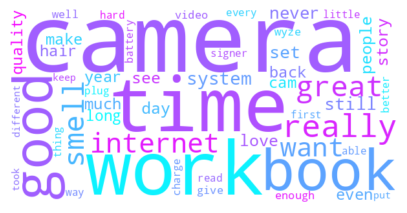

In [ ]:
plt.figure(figsize=(5, 4))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Identify top five best selling products (highest review count) for each one of the five categories:

In [ ]:
groupby_cat_asin = all_reviews.groupby(["main_category", "asin"]).size().reset_index(name="review_count")

top_products = []

#find top 5 selling products for each category
for category in product_categories:
    top5_per_cat = groupby_cat_asin[groupby_cat_asin["main_category"] == category] \
        .sort_values("review_count", ascending=False) \
        .head(5)
    top_products.append(top5_per_cat)

top_products_df = pd.concat(top_products, ignore_index=True)

In [ ]:
top_products_with_features = pd.merge(
    top_products_df,
    all_reviews[["asin", "parent_asin", "features"]],
    on="asin",
    how="left"
).drop_duplicates()

In [ ]:
for category in product_categories:
    print(f"\nTop 5 Best-Selling Products in {category}:")
    print(top_products_with_features[top_products_with_features["main_category"] == category][["asin", "review_count", "features"]])


Top 5 Best-Selling Products in Books:
           asin  review_count  \
0    B00RPM9MJ6           347   
347  B01LZFL63S           319   
666  0394800184           128   
794  B08F4GYM8W           116   
910  0545852501            85   

                                              features  
0    ['This book is RATED-R FOR LANGUAGE by the pub...  
347  ["Featuring an exclusive excerpt from Kate Qui...  
666  ['The must-have, heartwarming and hilarious cl...  
794  ['“Part detective tale, part thriller…touching...  
910  ['A true story from Raina Telgemeier, the #1',...  

Top 5 Best-Selling Products in Kindle_Store:
            asin  review_count  \
995   B087ZXSPGJ           260   
1255  B01M4GE64D           138   
1393  B003I1WY2A            92   
1485  B0023SDPS6            49   
1534  B004KZPK92            49   

                                               features  
995   ['"The Bestselling Hardcover Novel of the Year...  
1255  ['Come Sundown', 'named as one of Whoopi Goldb.

Most common features (words) in the top five selling products for each category:

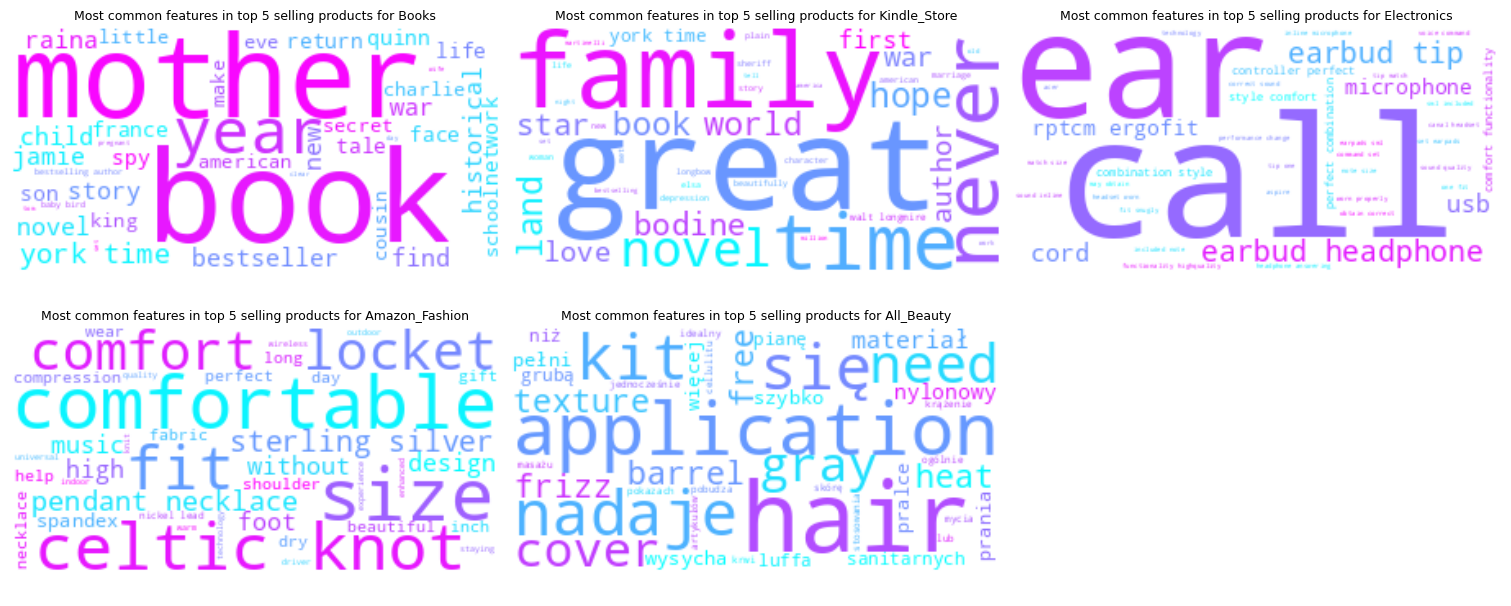

In [ ]:
categories = top_products_with_features["main_category"].unique()
num_categories = len(categories)
cols = 3
rows = ceil(num_categories / cols)

fig, ax = plt.subplots(rows, cols, figsize=(cols * 5, rows * 3), constrained_layout=True)
ax = ax.flatten()

for i, category in enumerate(categories):
    cat_data = top_products_with_features[top_products_with_features["main_category"] == category]
    feature_words = []

    for row in cat_data["features"]:           #Clean features
        if isinstance(row, str):
            feature_words.append(text_preprocessing(row))
        elif isinstance(row, list):
            feature_words.extend(text_preprocessing(str(f)) for f in row)


    feature_text = " ".join(feature_words)
    wordcloud = WordCloud(width=300, height=150, background_color="white", colormap="cool", max_words=40).generate(feature_text)

    ax[i].imshow(wordcloud, interpolation="bilinear")
    ax[i].set_title(f"Most common features in top 5 selling products for {category}", fontsize=9)
    ax[i].axis("off")

for j in range(i + 1, len(ax)):
    ax[j].axis("off")
plt.show()

Average product rating evolution over time:

In this section we create line plots that depict the average rating (from all products), per category. All data comes from the time period between 01-2016 and 12-2022.

In [ ]:
products_per_year_category = (
    all_reviews
    .groupby(['main_category', 'year'])['asin']
    .nunique()
    .reset_index()
    .rename(columns={'asin': 'num_products'})
)
print(products_per_year_category)

     main_category  year  num_products
0       All_Beauty  2016           270
1       All_Beauty  2017           317
2       All_Beauty  2018           358
3       All_Beauty  2019           412
4       All_Beauty  2020           435
5       All_Beauty  2021           450
6       All_Beauty  2022           384
7   Amazon_Fashion  2016           393
8   Amazon_Fashion  2017           480
9   Amazon_Fashion  2018           562
10  Amazon_Fashion  2019           681
11  Amazon_Fashion  2020           600
12  Amazon_Fashion  2021           625
13  Amazon_Fashion  2022           589
14           Books  2016           416
15           Books  2017           372
16           Books  2018           361
17           Books  2019           332
18           Books  2020           271
19           Books  2021           269
20           Books  2022           222
21     Electronics  2016           368
22     Electronics  2017           364
23     Electronics  2018           379
24     Electronics  2019 

Average rating trend per year:

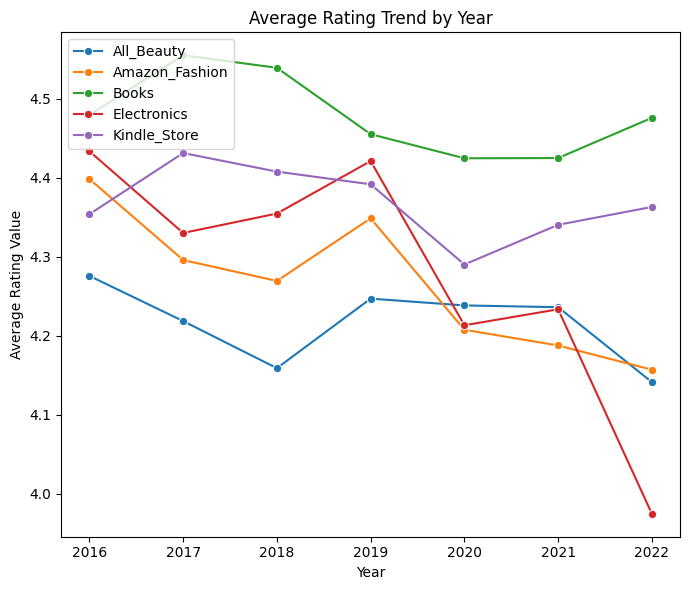

In [ ]:
filtered_reviews = all_reviews[all_reviews['year'] <= 2022].copy()
yearly_trend = (
    filtered_reviews
    .groupby(['main_category', 'year'])['rating']        #Find average ratings per year and category
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7, 6))
sns.lineplot(data=yearly_trend, x='year', y='rating', hue='main_category', marker='o', ax=ax)

ax.set_title('Average Rating Trend by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Average Rating Value')
ax.set_xticks(sorted(filtered_reviews['year'].unique()))
ax.legend(title=None, loc='upper left')

plt.tight_layout()
plt.show()

Average rating trend over the months of 2020 and 2021:

In [ ]:
monthly_reviews = all_reviews[all_reviews['year'].isin([2020, 2021])].copy()
monthly_reviews['month'] = pd.to_datetime(monthly_reviews['year_month']).dt.month_name()

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_trend = (
    monthly_reviews
    .groupby(['main_category', 'year', 'month'])['rating']
    .mean()
    .reset_index()
)

monthly_trend['month'] = pd.Categorical(monthly_trend['month'], categories=month_order, ordered=True)
monthly_trend.sort_values(['year', 'month'], inplace=True)

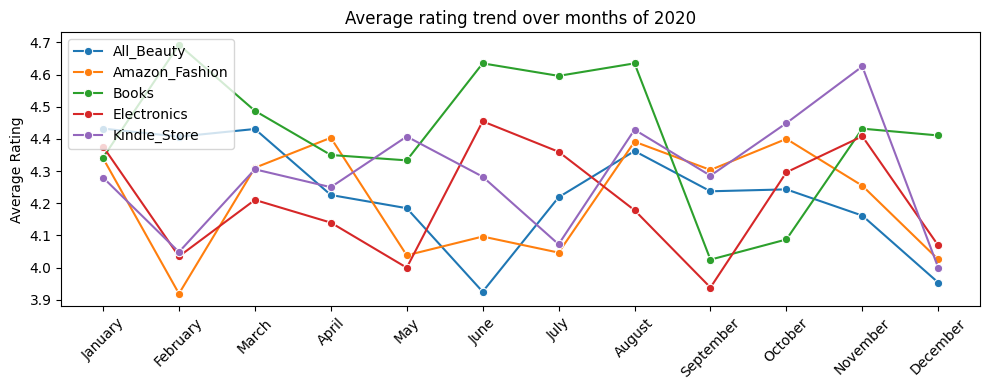

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    data=monthly_trend[monthly_trend['year'] == 2020],
    x='month', y='rating', hue='main_category',
    marker='o', ax=ax
)

ax.set_title(f'Average rating trend over months of 2020')
ax.set_ylabel('Average Rating')
ax.set_xlabel(None)
ax.legend(title=None, loc='upper left')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

* We observe that Books reach their highest average ratings during holiday months and seasonal breaks (January, June-August).

* Amazon_Fashion, All_Beauty and Electronics ratings remain below 4.5 throughout the year.

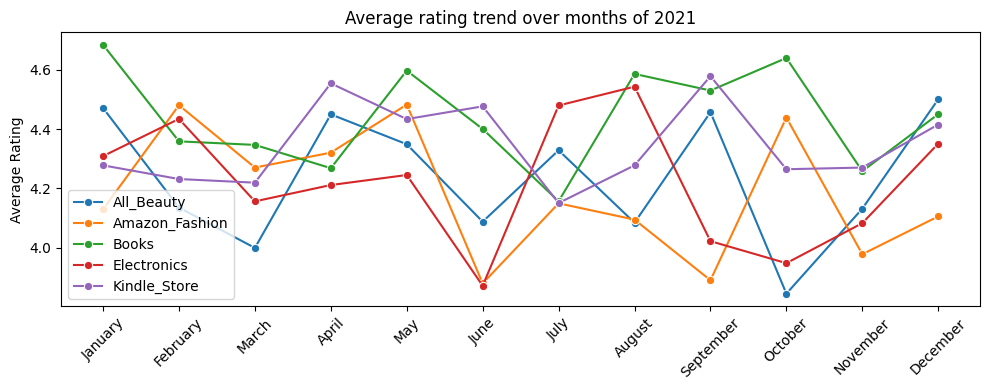

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    data=monthly_trend[monthly_trend['year'] == 2021],
    x='month', y='rating', hue='main_category',
    marker='o', ax=ax
)

ax.set_title(f'Average rating trend over months of 2021')
ax.set_xlabel(None)
ax.set_ylabel('Average Rating')
ax.legend(title=None, loc='lower left')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

* Electronics and Books peak during  back-to-school shopping periods, such as late summer months (July-August for electronics) and beggining of fall (August-October for books).


* Kindle_Store's average ratings are higher in 2021 than  in 2020.

Question 2 - Extracting sentiment scores from ratings:

In this part, we are using a pre-trained model from Hugging face to classify our reviews as Positive, Negative and Neutral. We will use ``` nlptown/bert-base-multilingual-uncased-sentiment ```, which is a model fine-tuned for sentiment analysis on product reviews. It predicts the sentiment by outputing the number of stars a product would receive as rating. We map the predicted number of stars to a sentiment as follows:

* 1 or 2 stars : NEGATIVE
* 3 stars : NEUTRAL
* 4 or 5 stars : POSITIVE

In [ ]:
from tqdm import tqdm
def map_to_sentiment(texts):
    processed_texts = [str(t) for t in texts]

    batch_size = 32
    labels = []

    for i in tqdm(range(0, len(processed_texts), batch_size), desc="Processing reviews"):
        batch = processed_texts[i:i+batch_size]
        results = sentiment_pipeline(batch)

        for r in results:
            stars = int(r["label"].split()[0])
            if stars <= 2:
                labels.append("NEGATIVE")
            elif stars == 3:
                labels.append("NEUTRAL")
            else:
                labels.append("POSITIVE")

    return labels

In [ ]:
sentiment_pipeline = pipeline("sentiment-analysis",model="nlptown/bert-base-multilingual-uncased-sentiment",
                              batch_size=32,truncation=True)

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/669M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
dfs = []
for category in product_categories:
    df = pd.read_csv(f"data/{category}_data.csv")
    df["sentiment_label"] = map_to_sentiment(df["text"].tolist())
    dfs.append(df)

all_reviews = pd.concat(dfs, ignore_index=True)

Processing reviews: 100%|██████████| 157/157 [00:15<00:00, 10.35it/s]


sentiment_label
POSITIVE    19032
NEGATIVE     3395
NEUTRAL      2571
Name: count, dtype: int64


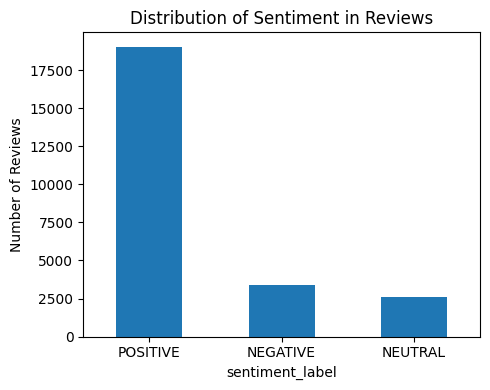

In [ ]:
print(all_reviews['sentiment_label'].value_counts())
plt.figure(figsize=(5, 4))
all_reviews['sentiment_label'].value_counts().plot(kind='bar')

plt.title('Distribution of Sentiment in Reviews')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.grid(False)
plt.tight_layout()
plt.show()

We normalize the review rating (from 1-5 to a scale of 0-1)

In [ ]:
all_reviews["normalized_rating"] = (all_reviews["rating"] - 1) / 4
final_df = all_reviews[["asin", "rating", "normalized_rating", "sentiment_label"]].copy()

To calculate the final sentiment score we combine both the normalized rating value and the sentiment extracted from the model.

We choose a higher weight for the sentiment value extracted from the pre-trained model, as text reflects more accurately the sentiment than a simple rating does.

In [ ]:
sentiment_map = {"NEGATIVE": 0.0,"NEUTRAL": 0.5,"POSITIVE": 1.0}

w1 = 0.6          #weight for model's sentiment
w2 = 0.4          #weight for normalized rating
final_df["sentiment_score"] = (w1 * final_df["sentiment_label"].map(sentiment_map) + w2 * final_df["normalized_rating"])

In [ ]:
final_scores_df = final_df[["asin", "sentiment_score"]]

output_path = "final_sentiment_scores.csv"
final_scores_df.to_csv("/content/final_sentiment_scores.csv", index=False)

In [ ]:
!cp /content/final_sentiment_scores.csv  /content/drive/MyDrive/final_sentiment_scores.csv

### Part 2 - Learning Tasks:


Question 1 - Clustering:

In the following task we aim to identify clusters within each product category using the k-means algorithm.

In [ ]:
product_categories = ["Books", "Kindle_Store", "Electronics", "Amazon_Fashion","All_Beauty"]

stop_words = set(stopwords.words("english"))
stop_words.update([
    "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten",
    "amazon", "product", "buy", "bought", "purchase", "item", "use", "used", "get"])

product_categories = ["Books", "Kindle_Store", "Electronics", "Amazon_Fashion","All_Beauty"]
lemmatizer = WordNetLemmatizer()

def text_preprocessing(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2 and w != "s"]
    return " ".join(tokens)

In [ ]:
#Scales the input columns
def scale_numeric_features(df, columns):
    scaler = StandardScaler()
    scaled_values = scaler.fit_transform(df[columns])
    for i, col in enumerate(columns):
        df[f"norm_{col}"] = scaled_values[:, i]
    return df

In [ ]:
#Converts each word to an embedding and then averages all embeddings 
def create_embeddings(text, model):
    words = text.split()
    vectors = [model[word] for word in words if word in model]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(model.vector_size)

Before applying the k-means algorithm we clean the ```description``` column and we standardize the columns ```price``` and ```average_rating```so that a common scale is used.

In [ ]:
cleaned_dfs = []
for category in product_categories:
    df = pd.read_csv(f"data/{category}_data.csv")
    df["description"] = df["description"].apply(lambda x: text_preprocessing(" ".join(ast.literal_eval(x))) if isinstance(x, str) and x.startswith("[") else text_preprocessing(x))
    df = scale_numeric_features(df, ["price", "average_rating"])
    cleaned_dfs.append(df)

all_data = pd.concat(cleaned_dfs, ignore_index=True)

We are using TF-IDF vectorization to represent the ```description``` column. We experiment with different values of $k \in [2, 8] $ and compute the silhouette scores, which are very low (< 0.3). This is an idication of low-quality clusters. For better clustering we decide to use FastText embeddings.

For each value of k, we compute the silhouette score and plot the Within-Cluster Sum of Squares (WCSS), which is the sum of the squared distances between each data point and the centroid of its cluster, added over all clusters.

In [ ]:
# !pip install gensim

In [ ]:
import gensim.downloader as api
fasttext_model = api.load("fasttext-wiki-news-subwords-300")

[==================================================] 100.0% 958.5/958.4MB downloaded


In [ ]:
from tqdm import tqdm
tqdm.pandas()
all_data["fasttext_emb"] = all_data["description"].progress_apply(lambda text: create_embeddings(text, fasttext_model))

100%|██████████| 24998/24998 [00:12<00:00, 2076.96it/s]



=== Clustering for category: Books ===
  k = 2 → Silhouette Score = 0.455
  k = 3 → Silhouette Score = 0.475
  k = 4 → Silhouette Score = 0.364
  k = 5 → Silhouette Score = 0.397
  k = 6 → Silhouette Score = 0.399
  k = 7 → Silhouette Score = 0.369
  k = 8 → Silhouette Score = 0.358
→ Best k for Books: 3 (Silhouette Score = 0.475)


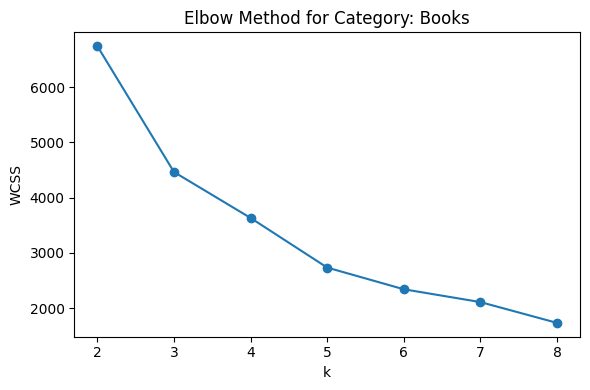


=== Clustering for category: Kindle_Store ===
  k = 2 → Silhouette Score = 0.364
  k = 3 → Silhouette Score = 0.350
  k = 4 → Silhouette Score = 0.371
  k = 5 → Silhouette Score = 0.386
  k = 6 → Silhouette Score = 0.363
  k = 7 → Silhouette Score = 0.351
  k = 8 → Silhouette Score = 0.369
→ Best k for Kindle_Store: 5 (Silhouette Score = 0.386)


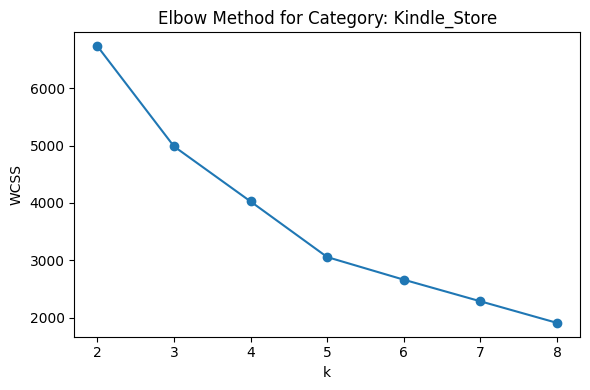


=== Clustering for category: Electronics ===
  k = 2 → Silhouette Score = 0.448
  k = 3 → Silhouette Score = 0.482
  k = 4 → Silhouette Score = 0.484
  k = 5 → Silhouette Score = 0.371
  k = 6 → Silhouette Score = 0.392
  k = 7 → Silhouette Score = 0.392
  k = 8 → Silhouette Score = 0.434
→ Best k for Electronics: 4 (Silhouette Score = 0.484)


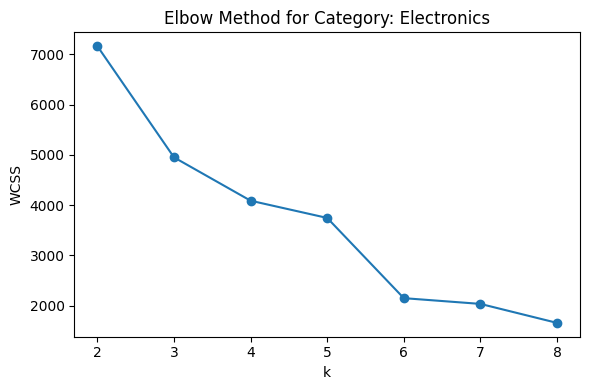


=== Clustering for category: Amazon_Fashion ===
  k = 2 → Silhouette Score = 0.422
  k = 3 → Silhouette Score = 0.427
  k = 4 → Silhouette Score = 0.457
  k = 5 → Silhouette Score = 0.448
  k = 6 → Silhouette Score = 0.451
  k = 7 → Silhouette Score = 0.452
  k = 8 → Silhouette Score = 0.397
→ Best k for Amazon_Fashion: 4 (Silhouette Score = 0.457)


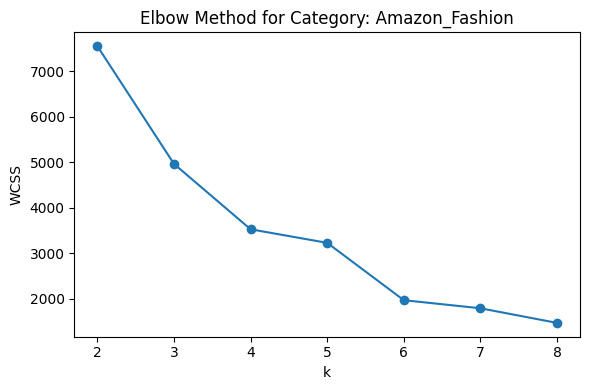


=== Clustering for category: All_Beauty ===
  k = 2 → Silhouette Score = 0.460
  k = 3 → Silhouette Score = 0.468
  k = 4 → Silhouette Score = 0.326
  k = 5 → Silhouette Score = 0.341
  k = 6 → Silhouette Score = 0.337
  k = 7 → Silhouette Score = 0.318
  k = 8 → Silhouette Score = 0.310
→ Best k for All_Beauty: 3 (Silhouette Score = 0.468)


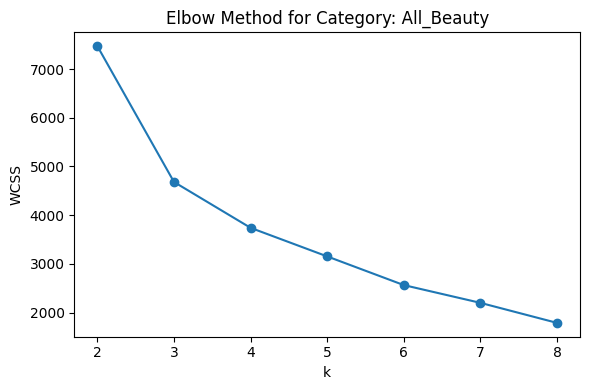

In [ ]:
k_values = range(2, 9)
best_k_per_category = {}

for category in product_categories:
    print(f"\n=== Clustering for category: {category} ===")

    category_data = all_data[all_data["main_category"] == category].copy()
    numeric_data = category_data[["norm_price", "norm_average_rating"]].values
    embeddings = np.vstack(category_data["fasttext_emb"].values)
    full_matrix = np.hstack([embeddings, numeric_data])

    inertia_values = []
    best_score = -1
    best_k = None

    for k in k_values:
        kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init="auto")
        labels = kmeans.fit_predict(full_matrix)
        inertia_values.append(kmeans.inertia_)
        score = silhouette_score(full_matrix, labels)
        print(f"  k = {k} → Silhouette Score = {score:.3f}")

        if score > best_score:
            best_score = score
            best_k = k

    best_k_per_category[category] = best_k
    print(f"→ Best k for {category}: {best_k} (Silhouette Score = {best_score:.3f})")

    plt.figure(figsize=(6, 4))
    plt.plot(k_values, inertia_values, marker='o')
    plt.title(f"Elbow Method for Category: {category}")
    plt.xlabel("k")
    plt.ylabel("WCSS")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

For all product categories there is not a clear elbow point, which is the case for most real world datasets. We select the optimal k value for each category based on the silhouette score. 

In [ ]:
print("\n=== Best k per category ===")
for category, best_k in best_k_per_category.items():
    print(f"{category}: k = {best_k}")


=== Best k per category ===
Books: k = 3
Kindle_Store: k = 5
Electronics: k = 4
Amazon_Fashion: k = 4
All_Beauty: k = 3


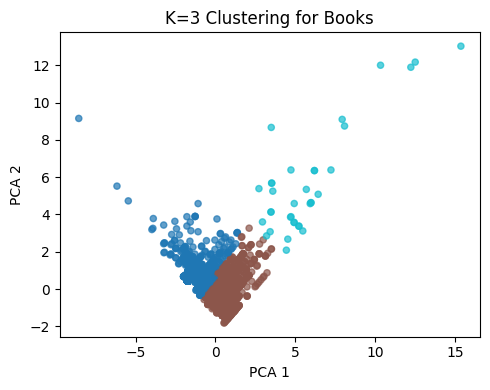

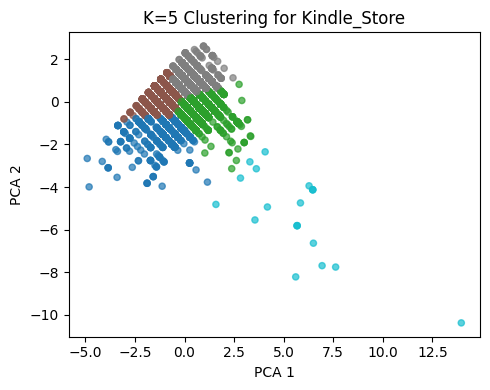

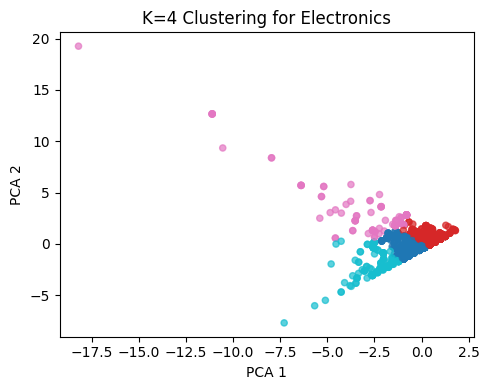

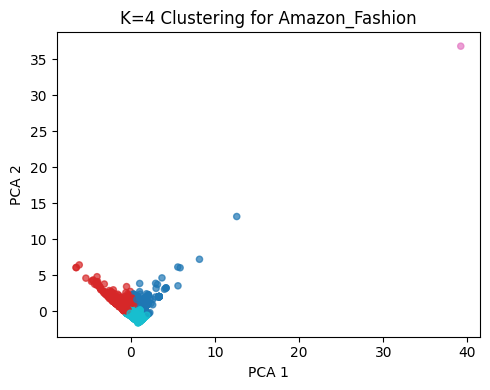

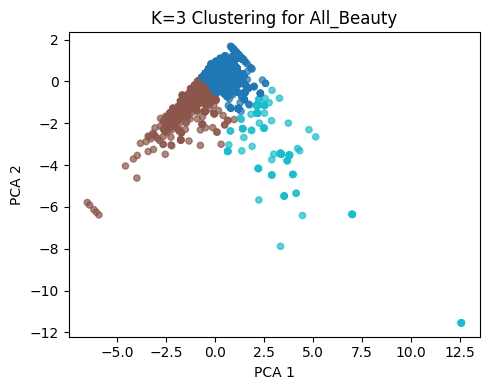

In [ ]:
category_cluster_data = {}

for category in product_categories:
    k = best_k_per_category[category]
    category_data = all_data[all_data["main_category"] == category].copy()

    numeric_data = category_data[["norm_price", "norm_average_rating"]].values
    embeddings = np.vstack(category_data["fasttext_emb"].values)
    full_matrix = np.hstack([embeddings, numeric_data])

    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init="auto")
    labels = kmeans.fit_predict(full_matrix)
    category_data["cluster"] = labels
    category_cluster_data[category] = category_data

    pca = PCA(n_components=2)
    reduced_features = pca.fit_transform(full_matrix)

    plt.figure(figsize=(5, 4))
    plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap="tab10", s=20, alpha=0.7)
    plt.title(f"K={k} Clustering for {category}")
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

In [ ]:
for category in product_categories:
    k = best_k_per_category[category]
    df = category_cluster_data[category]
    print(f"\n=== Cluster Analysis for {category} (k = {k}) ===")

    for cluster_id in range(k):
        cluster_items = df[df["cluster"] == cluster_id]
        avg_price = cluster_items["price"].mean()
        avg_rating = cluster_items["average_rating"].mean()

        print(f"\nCluster {cluster_id}")
        print(f"Products: {len(cluster_items)}")
        print(f"Average Price: {avg_price:.2f}")
        print(f"Average Rating: {avg_rating:.2f}")


=== Cluster Analysis for Books (k = 3) ===

Cluster 0
Products: 1452
Average Price: 10.49
Average Rating: 4.17

Cluster 1
Products: 3513
Average Price: 14.38
Average Rating: 4.67

Cluster 2
Products: 35
Average Price: 128.85
Average Rating: 4.55

=== Cluster Analysis for Kindle_Store (k = 5) ===

Cluster 0
Products: 573
Average Price: 10.50
Average Rating: 4.02

Cluster 1
Products: 1858
Average Price: 11.85
Average Rating: 4.48

Cluster 2
Products: 1195
Average Price: 4.21
Average Rating: 4.28

Cluster 3
Products: 1354
Average Price: 6.41
Average Rating: 4.64

Cluster 4
Products: 20
Average Price: 45.12
Average Rating: 4.47

=== Cluster Analysis for Electronics (k = 4) ===

Cluster 0
Products: 2124
Average Price: 44.48
Average Rating: 4.27

Cluster 1
Products: 2557
Average Price: 44.19
Average Rating: 4.62

Cluster 2
Products: 137
Average Price: 736.98
Average Rating: 4.49

Cluster 3
Products: 182
Average Price: 109.29
Average Rating: 3.69

=== Cluster Analysis for Amazon_Fashion (k =

Question 2 - Recommendation System:

In [ ]:
chosen_category = "Books"

* Collaborative Filtering: CF recommends items based on the preferences of similar users (user-based) or similar items (item-based).

User-based Collaborative Filtering:

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
#splitting data to train and test sets
cf_df = all_data[all_data["main_category"] == chosen_category].copy()
cf_df = cf_df[["user_id", "asin", "rating"]]
train_df, test_df = train_test_split(cf_df, test_size=0.2, random_state=42)

In [ ]:
#User-item matrix of users and products(asin), filling missing values with 0
user_item_matrix = train_df.pivot_table(index="user_id", columns="asin", values="rating").fillna(0)

In [ ]:
user_similarity = cosine_similarity(user_item_matrix)
user_similarity_df = pd.DataFrame(user_similarity, index=user_item_matrix.index, columns=user_item_matrix.index)

In [ ]:
#Returns predicted rating of user_id for item_id, based on rating of similar users for item_id
def get_user_based_rating(user_id, item_id, k=5):

    if user_id not in user_item_matrix.index:
        return np.nan
    if item_id not in user_item_matrix.columns:
        return np.nan

    #get similarity scores between user_id and all other users
    similarity_scores = user_similarity_df[user_id].drop(user_id)

    users_who_rated = user_item_matrix[user_item_matrix[item_id] > 0]  #find users that have rated item_id

    if users_who_rated.empty:
        return np.nan

    #find those that have have rated item_id and have a similarity score with user_id
    valid_users = users_who_rated.index.intersection(similarity_scores.index)

    if valid_users.empty:
        return np.nan

    similarity_scores = similarity_scores[valid_users]
    similarity_scores = similarity_scores[similarity_scores > 0]      #keep the ones with high similarity scores

    if similarity_scores.empty:
        return np.nan

    top_k_users = similarity_scores.sort_values(ascending=False).head(k)

    ratings = user_item_matrix.loc[top_k_users.index, item_id]  #ratings of top k similar users
    similarities = top_k_users.values             #similarity to user_id

    # Compute weighted average rating
    predicted_rating = np.dot(similarities, ratings) / np.sum(similarities)
    return predicted_rating

For every user–item pair in the test set, we find the k users most similar to the target user who have also rated the item, and we predict the rating as the average of their ratings for the item.

In [ ]:
# Predict ratings for the test set
test_df["predicted_rating"] = test_df.apply(lambda row: get_user_based_rating(row["user_id"], row["asin"], k=5), axis=1)
print("Actual vs. Predicted Ratings (where prediction is available):\n")
print(test_df[test_df["predicted_rating"].notna()][["rating", "predicted_rating", "asin"]])

Actual vs. Predicted Ratings (where prediction is available):

      rating  predicted_rating        asin
3321     5.0               4.0  B0871L3J4J
655      2.0               5.0  1535925566
3274     5.0               4.6  1250094461
2584     4.0               4.4  B00RPM9MJ6
221      5.0               5.0  0394800184
4324     5.0               4.2  1250165342
4346     5.0               5.0  0345502035
1018     5.0               4.0  1483836088


Generating top five product recommendations for a given user:

In [ ]:
#Returns the predicted scores for all items the user has not yet interacted with
def get_user_based_scores_for_unrated_items(user_id, k=5):
    if user_id not in user_item_matrix.index:
        return []

    user_ratings = user_item_matrix.loc[user_id]
    unrated_items = user_ratings[user_ratings == 0].index       #get items the user has not yet rated on

    recommendations = []

    for item_id in unrated_items:                #for all unrated items
        predicted_rating = get_user_based_rating(user_id, item_id, k)      #get a prediction based on user similarity
        if not np.isnan(predicted_rating):
            recommendations.append((item_id, predicted_rating))

    return recommendations

In [ ]:
def recommend_top_k_user_based_items(user_id, k=5):
    all_scores = get_user_based_scores_for_unrated_items(user_id, k)
    all_scores = [item for item in all_scores if item[1] > 3]
    all_scores.sort(key=lambda x: x[1], reverse=True)          #return top-k item with higher predicted rating
    return all_scores[:k]

In [ ]:
test_users = test_df["user_id"].unique()
for user_id in test_users:
    top_k = recommend_top_k_user_based_items(user_id, k=5)
    if top_k:
      print(f"\nTop-5 User-Based CF Recommendations for User {user_id}:")
      for asin, score in top_k:
          print(f"ASIN: {asin}, Predicted Rating: {score:.2f}")


Top-5 User-Based CF Recommendations for User AEYVBL3BE4NLNJELSLNQIC56LOVQ:
ASIN: 1250295971, Predicted Rating: 5.00

Top-5 User-Based CF Recommendations for User AEVAL4LL5KJKNE7K6IIUUDEPLJVA:
ASIN: 1250094461, Predicted Rating: 5.00
ASIN: B01LZFL63S, Predicted Rating: 5.00

Top-5 User-Based CF Recommendations for User AGZXNXUWL7CHLHNL4JSBL52FHCRQ:
ASIN: 0593134826, Predicted Rating: 5.00
ASIN: 1250094461, Predicted Rating: 5.00
ASIN: B01LZFL63S, Predicted Rating: 5.00

Top-5 User-Based CF Recommendations for User AGQWEGYS6ZZP2FLT5YVKCER6LZNQ:
ASIN: 1643852914, Predicted Rating: 4.00

Top-5 User-Based CF Recommendations for User AGVDZINSDI7FQ2X7TNGH57D3X5YQ:
ASIN: 0060274778, Predicted Rating: 5.00
ASIN: 1250109167, Predicted Rating: 5.00
ASIN: 1250624681, Predicted Rating: 5.00
ASIN: 1426791496, Predicted Rating: 5.00
ASIN: 1483836088, Predicted Rating: 5.00

Top-5 User-Based CF Recommendations for User AGE522R3Q7EE2UQ5VLYH4CT4VBBQ:
ASIN: 0684862093, Predicted Rating: 5.00
ASIN: 14926

Item-based Collaborative Filtering:

In [ ]:
train_df, test_df = train_test_split(cf_df, test_size=0.2, random_state=47)
user_item_matrix = train_df.pivot_table(index="user_id", columns="asin", values="rating").fillna(0)
item_user_matrix = user_item_matrix.T

In [ ]:
item_similarity = cosine_similarity(item_user_matrix)
item_similarity_df = pd.DataFrame(item_similarity, index=item_user_matrix.index, columns=item_user_matrix.index)

In [ ]:
#Returns predicted rating of user_id for item_id, based on ratings of user_id to items similar to item_id
def get_item_based_rating(user_id, item_id, k=5):

    if user_id not in user_item_matrix.index:
        return np.nan
    if item_id not in item_user_matrix.index:
        return np.nan

    #get similarity scores between the target item and all other items
    similarity_scores = item_similarity_df.loc[item_id].drop(item_id)

    user_ratings = user_item_matrix.loc[user_id]
    rated_items = user_ratings[user_ratings > 0].index        # get items the user has rated

    if rated_items.empty:
        return np.nan

    #get items most similar to the item_id, that the user has rated
    similar_rated_items = rated_items.intersection(similarity_scores.index)

    if similar_rated_items.empty:
        return np.nan

    similarity_scores = similarity_scores[similar_rated_items]
    similarity_scores = similarity_scores[similarity_scores > 0]     #keep items with positive similarity score

    if similarity_scores.empty:
        return np.nan

    top_k_items = similarity_scores.sort_values(ascending=False).head(k)
    top_k_ratings = user_ratings[top_k_items.index].values       #ratings of user_if for top k similar items
    top_k_similarities = top_k_items.values

    #Compute weighted average
    predicted_rating = np.dot(top_k_similarities, top_k_ratings) / np.sum(top_k_similarities)
    return predicted_rating

For every user-item pair in the test set, we find the k most similar items to the item in the test sample. From these items we keep the ones that the user has rated and based on the user's past ratings we infer the user's rating for the item.

In [ ]:
test_df["item_predicted_rating"] = test_df.apply(lambda row: get_item_based_rating(row["user_id"], row["asin"], k=5),axis=1)
print("Actual vs. Predicted Ratings (Item-Based) where prediction is available:\n")
print(test_df[test_df["item_predicted_rating"].notna()][["rating", "item_predicted_rating", "asin"]])

Actual vs. Predicted Ratings (Item-Based) where prediction is available:

      rating  item_predicted_rating        asin
1997     5.0                    5.0  4805314532
1999     5.0                    5.0  4805314532
4040     3.0                    4.0  B08F4GYM8W


Generating top five product recommendations for a given user:

In [ ]:
#Returns the predicted scores for all items the user has not yet interacted with
def get_item_based_scores_for_unrated_items(user_id, k=5):
    if user_id not in user_item_matrix.index:
        return []

    user_ratings = user_item_matrix.loc[user_id]
    unrated_items = user_ratings[user_ratings == 0].index      #get items the user has not yet rated

    recommendations = []

    for item_id in unrated_items:      #for all unrated items
        predicted_rating = get_item_based_rating(user_id, item_id, k=k)    #get a prediction based on item-similarity
        if not np.isnan(predicted_rating):
            recommendations.append((item_id, predicted_rating))

    return recommendations

In [ ]:
def recommend_top_k_item_based(user_id, k=5):
    all_scores = get_item_based_scores_for_unrated_items(user_id, k)
    #keep only items with rating above 3.0 (there is no point in recommending them otherwise)
    best_scores = [item for item in all_scores if item[1] > 3]
    best_scores.sort(key=lambda x: x[1], reverse=True)
    return best_scores[:k]       #return top-k items

In [ ]:
test_users = test_df["user_id"].unique()
for user_id in test_users:
    top_k = recommend_top_k_item_based(user_id, k=5)
    if top_k:
        print(f"\nTop-5 Item-Based CF Recommendations for User {user_id}:")
        for asin, score in top_k:
            print(f"ASIN: {asin}, Predicted Rating: {score:.2f}")


Top-5 Item-Based CF Recommendations for User AGRCXV4NM763VGZGD6BQ2VGNCJNA:
ASIN: 0711245436, Predicted Rating: 4.00
ASIN: 1483836088, Predicted Rating: 4.00

Top-5 Item-Based CF Recommendations for User AG5FGCIM6PBJX3JNDRKQMITZTIMA:
ASIN: 0060274778, Predicted Rating: 4.00
ASIN: 0062390015, Predicted Rating: 4.00
ASIN: 006242291X, Predicted Rating: 4.00
ASIN: 0345339495, Predicted Rating: 4.00
ASIN: 0451491750, Predicted Rating: 4.00

Top-5 Item-Based CF Recommendations for User AGZKZWIJEF7TMMDKJY25FLRQ6B3A:
ASIN: 0786915897, Predicted Rating: 4.00
ASIN: B08F4GYM8W, Predicted Rating: 4.00

Top-5 Item-Based CF Recommendations for User AEYUTWRDI6DZWLXIH45QPEXKKOAA:
ASIN: 1250155932, Predicted Rating: 4.00
ASIN: 1542726395, Predicted Rating: 4.00
ASIN: B004G5YX12, Predicted Rating: 4.00
ASIN: B01LZFL63S, Predicted Rating: 4.00
ASIN: B079DWJ4NH, Predicted Rating: 4.00

Top-5 Item-Based CF Recommendations for User AGZ7VUXZEQRQ7SZB4YC73IWMRUBQ:
ASIN: 0060274778, Predicted Rating: 4.00
ASIN:

* Content-Based Filtering:

In [ ]:
cbf_df = all_data[all_data["main_category"] == "Books"].copy()
cbf_df = cbf_df[["asin", "description", "norm_price","text","user_id"]].dropna()
cbf_df["text"] = cbf_df["text"].apply(text_preprocessing)

In [ ]:
import gensim.downloader as api
word2vec_model = api.load("word2vec-google-news-300")

In [ ]:
cbf_df["embedding"] = cbf_df["description"].apply(lambda x: create_embeddings(x, word2vec_model))

In [ ]:
def combine_features(row):
    return np.concatenate([row["embedding"], [row["norm_price"]]])

cbf_df["product_vectors"] = cbf_df.apply(combine_features, axis=1)

In [ ]:
#Creating training and test sets
cbf_train_df, cbf_test_df = train_test_split(cbf_df, test_size=0.2, random_state=42)
user_profiles = {}              # Building user profiles by taking the mean of product vectors
for user, group in cbf_train_df.groupby("user_id"):
    vectors = np.vstack(group["product_vectors"].values)
    user_profiles[user] = np.mean(vectors, axis=0)

In this part, we use content based filtering to make recommendations. We create a profile for each user by averaging the ```product_vectors``` column. For every item the user has not yet rated, we compute the similarity score between the user's profile and the item's vector. Finally, we recommend the top-k products with the highest similarity scores.

In [ ]:
# Returns similarity scores of all unrated products for a given user
def get_content_based_scores_for_unrated_items(user_id):
    if user_id not in user_profiles:
        return []

    rated = set(cbf_train_df[cbf_train_df["user_id"] == user_id]["asin"])     # get items the user has rated
    unrated = cbf_df[~cbf_df["asin"].isin(rated)].copy()                      # get unrated items from the full set
    unrated = unrated.drop_duplicates(subset="asin")

    if unrated.empty:
        return []

    user_vec = user_profiles[user_id]                  # get vector for user profile
    product_vecs = np.vstack(unrated["product_vectors"])

    # compute similarity between a user's profile and the product vectors
    similarity_scores = cosine_similarity([user_vec], product_vecs)[0]
    unrated["sim_scores"] = similarity_scores

    return list(zip(unrated["asin"], unrated["sim_scores"]))

In [ ]:
def top_k_content_based_recommendations(user_id, top_k=5):
    all_scores = get_content_based_scores_for_unrated_items(user_id)
    best_scores = [item for item in all_scores if item[1] > 3]
    best_scores.sort(key=lambda x: x[1], reverse=True)
    return best_scores[:top_k]

In [ ]:
test_users = cbf_test_df["user_id"].unique()
for user_id in test_users:
    top_k_cbf = top_k_content_based_recommendations(user_id, top_k=5)
    if top_k_cbf:
        print(f"\nTop-5 Content-Based Recommendations for User {user_id}:")
        for asin, score in top_k_cbf:
            print(f"ASIN: {asin}, Similarity Score: {score:.4f}")

* Hybrid Approach: For every product the user has not yet rated, we combine the predicted rating from the item-based collaborative filtering (CF) model with the similarity score from the content-based filtering (CBF) model into a single weighted score. We then recommend the top-k products with the highest weighted scores. We assign a weight of 0.4 to collaborative filtering and 0.6 to content-based filtering.

In [ ]:
cf_weight = 0.4
cbf_weight = 0.6
max_hybrid_score = (cf_weight * 5) + (cbf_weight * 1)
threshold = 1.5

test_users = test_df["user_id"].unique()

for user_id in test_users:
    cf_scores = dict(get_item_based_scores_for_unrated_items(user_id))
    cbf_scores = dict(get_content_based_scores_for_unrated_items(user_id))

    common_asins = set(cf_scores.keys()).intersection(cbf_scores.keys())

    user_recs = []
    for asin in common_asins:
        hybrid_score = (cf_weight * cf_scores[asin]) + (cbf_weight * cbf_scores[asin])
        if hybrid_score > threshold:
            user_recs.append((asin, hybrid_score))

    user_recs.sort(key=lambda x: x[1], reverse=True)
    top_k = user_recs[:5]

    if top_k:
        print(f"\nTop-5 Hybrid Recommendations for User {user_id}:")
        for asin, score in top_k:
            print(f"ASIN: {asin}, Hybrid Score: {score:.4f} / {max_hybrid_score:.2f}")


Top-5 Hybrid Recommendations for User AGRCXV4NM763VGZGD6BQ2VGNCJNA:
ASIN: 0711245436, Hybrid Score: 2.0230 / 2.60
ASIN: 1483836088, Hybrid Score: 1.9467 / 2.60

Top-5 Hybrid Recommendations for User AG5FGCIM6PBJX3JNDRKQMITZTIMA:
ASIN: 1501197428, Hybrid Score: 2.1606 / 2.60
ASIN: 0451491750, Hybrid Score: 2.1598 / 2.60
ASIN: 006242291X, Hybrid Score: 2.1376 / 2.60
ASIN: 0062390015, Hybrid Score: 2.1118 / 2.60
ASIN: 0345339495, Hybrid Score: 2.1010 / 2.60

Top-5 Hybrid Recommendations for User AHCKJN7BM7AH67UDRPN3CVNHHRTA:
ASIN: 1465461744, Hybrid Score: 1.5037 / 2.60

Top-5 Hybrid Recommendations for User AGZKZWIJEF7TMMDKJY25FLRQ6B3A:
ASIN: B08F4GYM8W, Hybrid Score: 2.1304 / 2.60
ASIN: 0786915897, Hybrid Score: 2.0763 / 2.60

Top-5 Hybrid Recommendations for User AEYUTWRDI6DZWLXIH45QPEXKKOAA:
ASIN: B01LZFL63S, Hybrid Score: 2.1715 / 2.60
ASIN: B079DWJ4NH, Hybrid Score: 2.1189 / 2.60
ASIN: B004G5YX12, Hybrid Score: 2.1043 / 2.60
ASIN: 1542726395, Hybrid Score: 2.0435 / 2.60
ASIN: 12501